# NEXUS OptiML 2026 - Product Return Prediction (combined, final pipeline)

**Merges** `nexus_return_prediction.ipynb` (drift-aware design, logical imputation, time-based CV, 4-model blend) and `kaggle4.ipynb` (bracketing features, price-in-cents fix, cyclic time features), plus new pieces found while analysing the data.

### The key facts that drive the design (all verified on the data)
1. **`promo_channel_code` is a trap.** Its return-rate spread is 35 points in 2023 (P5 44 % vs P0 9 %) but shrinks to ~5 points by Q4-2024 and every code converges to ~18 %. Local validation that includes it looks great, the future test months (2025) do not have it -> this is the usual cause of "0.64 locally, 0.55 on Kaggle". It is **never used as a plain feature**: it is dropped, or its fading effect is fed to the boosters as a fixed *offset* so they only learn the stable signal.
2. **What is stable over time:** store, product and customer return propensities (their rates from 2023 still predict Q4-2024), `channel`, `return_window_days`, `payment_method`, `quantity`, `items_in_order`, `discount`, `order_value`.
3. **Nulls are structural, not random:** many columns are constant inside an order (fill from sibling lines), `store` orders are always `in_store`, `session_clicks` is null only when there is no web session, `size_sqm` only for non-physical stores, `discount` is recoverable from `unit_price / list_price`.
4. **Data artefacts:** ~1.2 % of unit prices are in cents (x100), ~60 dirty category spellings, dirty customer regions, duplicated customer snapshots, date-only timestamps (minute = 01).

### Pipeline
audit -> clean + logical null filling -> features (order context / bracketing / calendar / label-free entity stats) -> OOF target encoding (single + pair keys + order-mates) -> **automatic feature-switch selection on the latest time fold** -> LightGBM + XGBoost + CatBoost + Logistic Regression -> rank blend -> `submission.csv`.

> **Honest expectation:** the validation AUC you see in section 8 is the number to trust. The labels carry limited stable signal (single entity effects are worth ~0.57-0.61 AUC each), so a Kaggle score of 0.80 is not something any pipeline can promise on this data; this notebook is built to get the best *honest* score and to avoid the promo-drift collapse.

Set `SAMPLE_FRAC < 1` (or `QUICK=1`) for a fast smoke test.

In [1]:
import os, gc, re, glob, time, difflib, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from scipy import sparse
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 90
try:    import xgboost as xgb;                          HAS_XGB = True
except ImportError: HAS_XGB = False
try:    from catboost import CatBoostClassifier, Pool;  HAS_CB = True
except ImportError: HAS_CB = False

cands = [os.environ.get('DATA_DIR', '.')] + glob.glob('/kaggle/input/*/') + glob.glob('/kaggle/input/*/*/') + ['/mnt/user-data/uploads']
DATA_DIR    = next(d for d in cands if os.path.exists(os.path.join(d, 'train.csv')))
SAMPLE_FRAC = float(os.environ.get('SAMPLE_FRAC', 1.0))           # <1 => hash-sample whole orders (fast run)
QUICK       = os.environ.get('QUICK', '0') == '1'
SEED        = 42
USE_XGB     = HAS_XGB and os.environ.get('USE_XGB', '1') == '1'
USE_CB      = HAS_CB  and os.environ.get('USE_CB',  '1') == '1'
USE_LR      = os.environ.get('USE_LR', '1') == '1'
LGB_ROUNDS, XGB_ROUNDS, CB_ROUNDS = (300, 300, 200) if QUICK else (4000, 3000, 1500)
FOLDS = [('2024-07-01', '2024-10-01'), ('2024-10-01', '2025-01-02')]   # each fold trains on everything BEFORE val_start; the last one is the most test-like
print('data dir:', DATA_DIR, '| sample:', SAMPLE_FRAC, '| xgb/cb/lr:', USE_XGB, USE_CB, USE_LR, '| quick:', QUICK)

data dir: . | sample: 1.0 | xgb/cb/lr: True True True | quick: False


## 1. Load data

In [2]:
rd = lambda f: pd.read_csv(f'{DATA_DIR}/{f}.csv')
tr, te, prd, st, cu, cal = rd('train'), rd('test'), rd('products'), rd('stores'), rd('customers'), rd('calendar')
if SAMPLE_FRAC < 1:
    h = lambda d: (pd.util.hash_pandas_object(d.order_id, index=False).values % 1000) < SAMPLE_FRAC * 1000
    tr, te = tr[h(tr)].reset_index(drop=True), te[h(te)].reset_index(drop=True)
print(tr.shape, te.shape, prd.shape, st.shape, cu.shape, cal.shape, '| return rate %.4f' % tr.returned.mean())
print('train', tr.order_ts.min(), '->', tr.order_ts.max(), '| test', te.order_ts.min(), '->', te.order_ts.max())

(1400005, 27) (479995, 26) (48677, 12) (454, 8) (204930, 9) (132, 7) | return rate 0.1805
train 2022-12-31 16:01:00 -> 2025-01-01 02:47:00 | test 2024-12-31 17:31:00 -> 2025-07-01 23:31:00


## 2. EDA - nulls, concept drift, what is stable over time

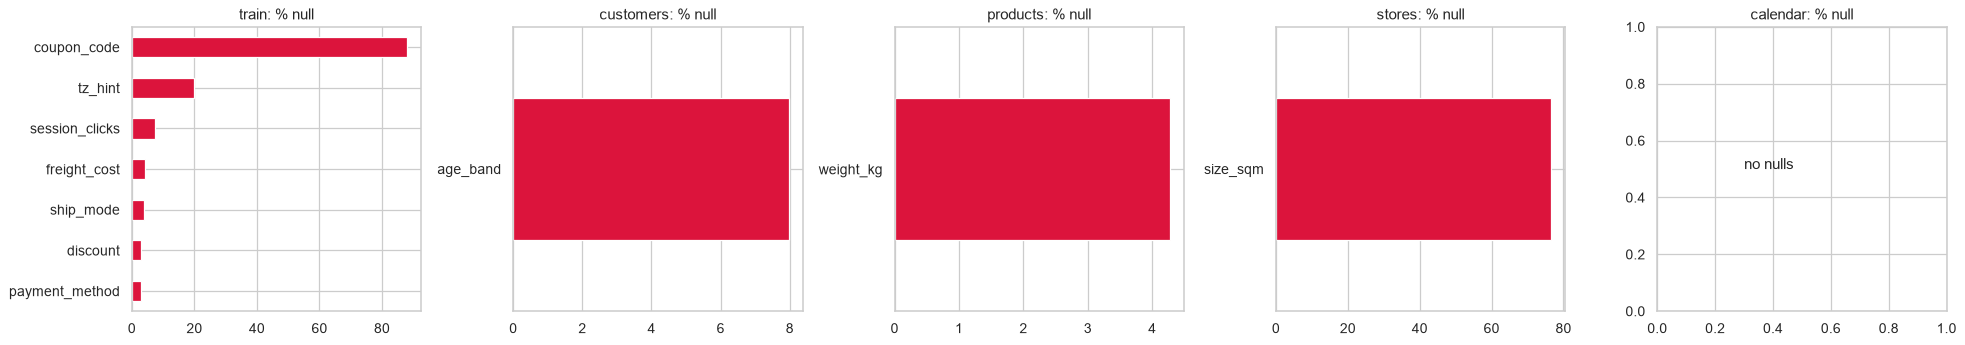

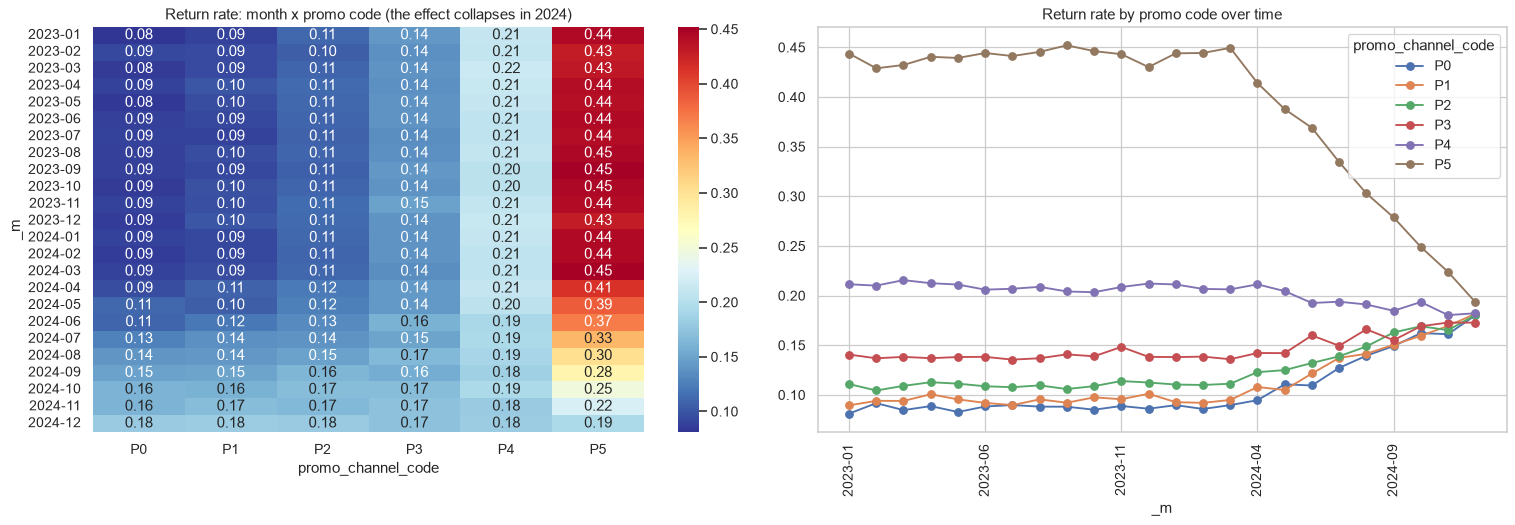

promo spread (P5-P0) by quarter: {'2023Q1': 0.349, '2023Q2': 0.355, '2023Q3': 0.358, '2023Q4': 0.353, '2024Q1': 0.358, '2024Q2': 0.285, '2024Q3': 0.167, '2024Q4': 0.054}


In [3]:
fig, ax = plt.subplots(1, 5, figsize=(22, 4))
for a, (n, d) in zip(ax, [('train', tr), ('customers', cu), ('products', prd), ('stores', st), ('calendar', cal)]):
    s = d.isnull().mean().mul(100); s = s[s > 0]
    (s.sort_values().plot.barh(ax=a, color='crimson') if len(s) else a.text(.3, .5, 'no nulls')); a.set_title(f'{n}: % null')
plt.tight_layout(); plt.show()
tr['_m'] = pd.to_datetime(tr.order_ts).dt.to_period('M').astype(str)
piv = tr[tr._m.between('2023-01', '2024-12')].pivot_table(index='_m', columns='promo_channel_code', values='returned', aggfunc='mean')
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(piv, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax[0]); ax[0].set_title('Return rate: month x promo code (the effect collapses in 2024)')
piv.plot(ax=ax[1], marker='o'); ax[1].set_title('Return rate by promo code over time'); ax[1].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()
print('promo spread (P5-P0) by quarter:', (piv['P5'] - piv['P0']).groupby(lambda m: m[:4] + 'Q' + str((int(m[5:]) - 1) // 3 + 1)).mean().round(3).to_dict())

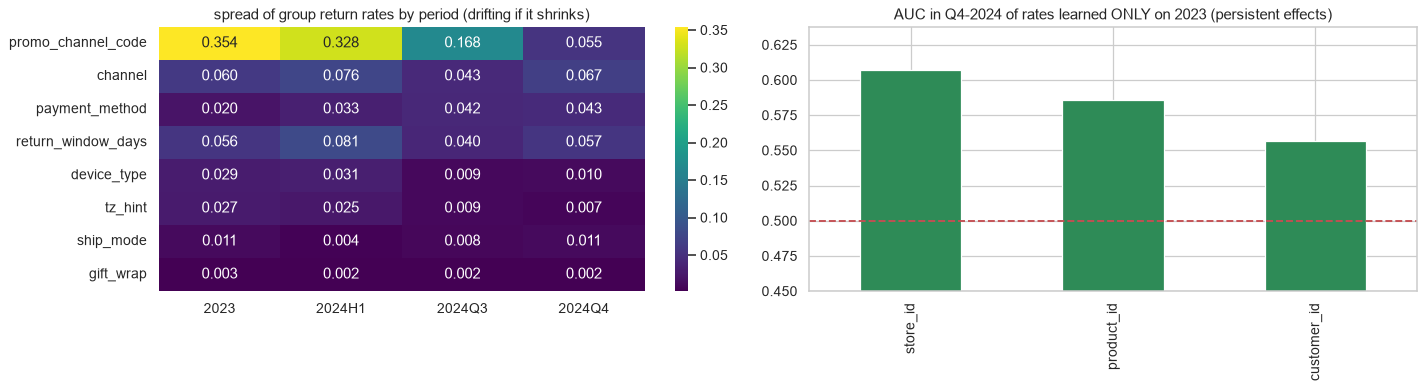

In [4]:
# stability check: spread of group return rates per period (a feature is safe only if its effect persists into the latest months)
per = pd.cut(pd.to_datetime(tr.order_ts), pd.to_datetime(['2022-12-01', '2024-01-01', '2024-07-01', '2024-10-01', '2025-01-02']), labels=['2023', '2024H1', '2024Q3', '2024Q4'])
rows = {}
for c in ['promo_channel_code', 'channel', 'payment_method', 'return_window_days', 'device_type', 'tz_hint', 'ship_mode', 'gift_wrap']:
    r = {}
    for p in per.cat.categories:
        g = tr[per == p].groupby(tr[c].fillna('NA')).returned.agg(['mean', 'size']); g = g[g['size'] >= 2000]; r[p] = g['mean'].max() - g['mean'].min()
    rows[c] = r
spread = pd.DataFrame(rows).T
# entity persistence: do rates learned in 2023 still rank customers/products/stores in Q4-2024?
q4 = tr[per == '2024Q4']; old = tr[per == '2023']; pers = {}
for c in ['store_id', 'product_id', 'customer_id']:
    g = old.groupby(c).returned.agg(['sum', 'count']); p0 = old.returned.mean(); m = (g['sum'] + 20 * p0) / (g['count'] + 20)
    pers[c] = roc_auc_score(q4.returned, q4[c].map(m).fillna(p0))
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.heatmap(spread, annot=True, fmt='.3f', cmap='viridis', ax=ax[0]); ax[0].set_title('spread of group return rates by period (drifting if it shrinks)')
pd.Series(pers).plot.bar(ax=ax[1], color='seagreen'); ax[1].axhline(0.5, color='r', ls='--'); ax[1].set_ylim(0.45, None); ax[1].set_title('AUC in Q4-2024 of rates learned ONLY on 2023 (persistent effects)')
plt.tight_layout(); plt.show()

## 3. Cleaning + logical null filling (multi-table)
| Problem | Fix |
|---|---|
| product `category` ~60 spellings | fuzzy-match to the frequent canonical classes |
| customer `region` dirty (case/space/typos) | fuzzy-match to the clean store-region list |
| duplicate customer rows (snapshots) | point-in-time join (tier/region valid at order time), `n_records`, `tier_changed` |
| `age_band` null | random and never present in another snapshot -> honest `unknown` + flag |
| `size_sqm` null (77 % of stores) | structural: non-physical stores -> 0 + `is_physical` |
| `weight_kg` null (food category 100 %) | regression on dimensions / price / packaging / supplier typical weight |
| `tz_hint`, `payment_method`, `ship_mode` null | **constant within an order** -> copy from sibling lines; store -> `in_store`; then customer / channel mode |
| `session_clicks` null | only for phone/POS devices and store/catalog channels (no web session) -> 0 + `has_session` |
| `freight_cost` null | `in_store` -> 0, else regression (quantity, ship mode, weight, fuel surcharge...) |
| `discount` null | recoverable from `unit_price / list_price` -> regression incl. the cleaned price ratio |
| unit price in cents (x100, 1.2 % of rows) | detected by `unit_price / list_price` in [60, 140] -> divide by 100 |
| calendar | stationary versions only (week changes, de-trended temperature, holiday distance); raw CPI / unemployment levels are time proxies and do not extrapolate |

In [5]:
key = lambda s: re.sub(r'[^a-z]', '', str(s).lower())
def canon_map(values, canon, cutoff=0.7):
    ck = {key(c): c for c in canon}; out = {}
    for v in pd.unique(values):
        k = key(v)
        if k in ck: out[v] = ck[k]
        else:
            r = difflib.get_close_matches(k, list(ck), 1, cutoff); out[v] = ck[r[0]] if r else v
    return out

def model_impute(df, target, feats, log=False, n_fit=300000, rounds=250, seed=0):
    '''Fill NaNs of df[target] with a LightGBM regressor trained on the observed rows (uses relations, not random values). Prints holdout R2.'''
    miss = df[target].isnull().values
    if not miss.any(): return df[target]
    X = df[feats].copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]): X[c] = X[c].astype('category').cat.codes
    yv = np.log1p(df[target].clip(lower=0)) if log else df[target]
    ok = np.where(~miss)[0]; fit = np.random.RandomState(seed).choice(ok, min(n_fit, len(ok)), replace=False); cut = int(.85 * len(fit))
    p = dict(objective='regression', learning_rate=0.08, num_leaves=63, min_child_samples=50, feature_fraction=0.8, verbose=-1, num_threads=-1, seed=seed)
    m = lgb.train(p, lgb.Dataset(X.iloc[fit[:cut]], yv.iloc[fit[:cut]]), rounds, valid_sets=[lgb.Dataset(X.iloc[fit[cut:]], yv.iloc[fit[cut:]])], callbacks=[lgb.early_stopping(25, verbose=False)])
    r2 = r2_score(yv.iloc[fit[cut:]], m.predict(X.iloc[fit[cut:]], num_iteration=m.best_iteration)); pr_ = m.predict(X[miss], num_iteration=m.best_iteration)
    out = df[target].copy(); out[miss] = np.expm1(pr_) if log else pr_
    print(f'  imputed {target}: {miss.sum():,} rows (holdout R2 {r2:.3f})'); return out

def clean_tables(pr, st, cu, cal):
    # products
    vc = pr.category.astype(str).map(key).value_counts(); top = vc[vc >= 1000].index.tolist()
    pr['cat'] = pr.category.astype(str).map(key).map({k: (k if k in top else (difflib.get_close_matches(k, top, 1, 0.0) or [k])[0]) for k in vc.index})
    print('category spellings', pr.category.nunique(), '->', pr.cat.nunique())
    for c in ['packaging_type', 'color']: pr[c] = pr[c].astype(str).str.strip().str.lower()
    pr['vol'] = pr.length_cm * pr.width_cm * pr.height_cm; pr['weight_missing'] = pr.weight_kg.isnull().astype('int8')
    sw = pr.groupby('supplier_code').weight_kg.median(); pr['sup_w'] = pr.supplier_code.map(sw)
    pr['weight_kg'] = model_impute(pr, 'weight_kg', ['length_cm', 'width_cm', 'height_cm', 'vol', 'list_price', 'packaging_type', 'color', 'review_count', 'sup_w'], log=True)
    pr['density'] = pr.weight_kg / (pr.vol + 1e-3); pr['price_to_cat_median'] = pr.list_price / pr.groupby('cat').list_price.transform('median')
    pr['launch_date'] = pd.to_datetime(pr.launch_date)
    # stores
    st['s_region'] = st.region.map(canon_map(st.region.unique(), list(st.region.unique())))
    st['is_physical'] = st.channel.isin(['store', 'catalog']).astype('int8')
    st['size_sqm'] = st.size_sqm.fillna(st.groupby('format').size_sqm.transform('median')).fillna(0)
    st['opened_date'] = pd.to_datetime(st.opened_date)
    # customers: canonical region, snapshots
    cu['c_region'] = cu.region.map(canon_map(cu.region.unique(), list(st.s_region.unique())))
    cu['record_updated_at'] = pd.to_datetime(cu.record_updated_at).astype('datetime64[ns]'); cu = cu.sort_values('record_updated_at').reset_index(drop=True)
    cu['age_missing'] = cu.age_band.isnull().astype('int8'); cu['age_band'] = cu.age_band.fillna('unknown'); cu['signup_date'] = pd.to_datetime(cu.signup_date)
    first = cu.drop_duplicates('customer_id', keep='first'); last = cu.drop_duplicates('customer_id', keep='last')
    stat = first[['customer_id', 'customer_type', 'signup_date', 'age_band', 'age_missing', 'newsletter_opt_in', 'preferred_contact', 'loyalty_tier', 'c_region']].rename(columns={'loyalty_tier': 'tier_first', 'c_region': 'region_first', 'customer_type': 'c_type'})
    stat['n_records'] = stat.customer_id.map(cu.groupby('customer_id').size()).astype('int8')
    stat['tier_changed'] = (stat.tier_first.values != stat.customer_id.map(last.set_index('customer_id').loyalty_tier).values).astype('int8')
    # calendar: stationary versions only
    cal['week_start'] = pd.to_datetime(cal.week_start).astype('datetime64[ns]'); cal = cal.sort_values('week_start').reset_index(drop=True)
    for c in ['cpi', 'fuel_price', 'unemployment', 'fuel_surcharge']: cal[c + '_chg'] = cal[c].diff().fillna(0)
    cal['temp_dev'] = cal.temperature_f - cal.temperature_f.rolling(52, min_periods=1, center=True).mean()
    ix = np.arange(len(cal)); hol = ix[cal.holiday_flag.values == 1]
    cal['wk_to_hol'] = [(hol[hol >= i].min() - i) if (hol >= i).any() else 26 for i in ix]; cal['wk_since_hol'] = [(i - hol[hol <= i].max()) if (hol <= i).any() else 26 for i in ix]
    return pr, st, cu, stat, cal

## 4. Build the order-line table (point-in-time joins, logical imputation, features)

In [6]:
def build(tr, te, pr, st, cu, cal):
    pr, st, cu_snap, cu_stat, cal = clean_tables(pr, st, cu, cal)
    tr = tr.drop(columns=['_m'], errors='ignore'); tr['is_train'] = 1; te['is_train'] = 0; te['returned'] = np.nan
    df = pd.concat([tr, te], ignore_index=True); df['_row'] = np.arange(len(df))
    df['ts'] = pd.to_datetime(df.order_ts).astype('datetime64[ns]')
    df['week_start'] = (df.ts.dt.normalize() - pd.to_timedelta(df.ts.dt.dayofweek, unit='D')).astype('datetime64[ns]')
    # customer snapshot valid at order time (tier / region change); earliest snapshot as fallback
    df = df.sort_values('ts'); df = pd.merge_asof(df, cu_snap[['customer_id', 'record_updated_at', 'c_region', 'loyalty_tier']], left_on='ts', right_on='record_updated_at', by='customer_id', direction='backward')
    df = df.sort_values('_row').reset_index(drop=True).drop(columns=['record_updated_at'])
    df = df.merge(cu_stat, on='customer_id', how='left'); df['snap_fallback'] = df.c_region.isnull().astype('int8')
    df['c_region'] = df.c_region.fillna(df.region_first); df['loyalty_tier'] = df.loyalty_tier.fillna(df.tier_first); df = df.drop(columns=['region_first'])
    df = df.merge(pr.drop(columns=['category', 'length_cm', 'width_cm', 'height_cm', 'sup_w']), on='product_id', how='left')
    df = df.merge(st.rename(columns={'channel': 's_channel', 'format': 's_format'}).drop(columns=['region']), on='store_id', how='left')
    df = df.merge(cal[['week_start', 'holiday_flag', 'temperature_f', 'fuel_surcharge', 'cpi_chg', 'fuel_price_chg', 'unemployment_chg', 'fuel_surcharge_chg', 'temp_dev', 'wk_to_hol', 'wk_since_hol']], on='week_start', how='left')

    # ---- flags first (missingness carries a little signal)
    for c in ['tz_hint', 'payment_method', 'ship_mode', 'discount', 'freight_cost', 'session_clicks']: df[c + '_miss'] = df[c].isnull().astype('int8')
    df['has_coupon'] = df.coupon_code.notnull().astype('int8')
    # ---- order-level attributes: copy from sibling lines of the same order
    for c in ['tz_hint', 'payment_method', 'ship_mode']: df[c] = df[c].fillna(df.groupby('order_id')[c].transform('first'))
    df.loc[df.ship_mode.isnull() & (df.channel == 'store'), 'ship_mode'] = 'in_store'
    cust_pm = df.dropna(subset=['payment_method']).groupby('customer_id').payment_method.agg(lambda s: s.mode().iat[0])
    ch_pm = df.groupby('channel').payment_method.agg(lambda s: s.mode().iat[0] if s.notnull().any() else 'card')
    df['payment_method'] = df.payment_method.fillna(df.customer_id.map(cust_pm)).fillna(df.channel.map(ch_pm))
    df['ship_mode'] = df.ship_mode.fillna(df.groupby('channel').ship_mode.transform(lambda s: s.mode().iat[0] if s.notnull().any() else 'standard'))
    df['tz_hint'] = df.tz_hint.fillna('unknown')                                        # missing completely at random -> explicit level
    df.loc[df.ship_mode == 'in_store', 'freight_cost'] = df.loc[df.ship_mode == 'in_store', 'freight_cost'].fillna(0.0)
    df['has_session'] = df.session_clicks.notnull().astype('int8')
    nosess = df.device_type.isin(['phone', 'pos']) | df.channel.isin(['store', 'catalog']); df.loc[nosess, 'session_clicks'] = df.loc[nosess, 'session_clicks'].fillna(0)
    # ---- price artefact: ~1.2 % of unit prices are in cents (x100)
    df['pr_raw'] = df.unit_price / df.list_price
    df['price_cents'] = ((df.pr_raw >= 60) & (df.pr_raw <= 140)).astype('int8')
    df['up'] = np.where(df.price_cents == 1, df.unit_price / 100.0, df.unit_price).astype('float32')
    df['price_ratio'] = df.up / df.list_price; df['lq'] = np.log1p(df.quantity)
    # ---- model-based imputation from related tables
    ctx = ['channel', 'ship_mode', 'cat', 'promo_channel_code', 's_region', 'c_region', 'c_type', 'loyalty_tier', 'lq', 'items_in_order', 'up', 'list_price', 'price_ratio', 'weight_kg', 'fuel_surcharge', 'return_window_days', 'device_type', 'payment_method']
    df['session_clicks'] = model_impute(df, 'session_clicks', ['device_type', 'channel', 'items_in_order', 'lq'], seed=1)
    df['freight_cost'] = model_impute(df, 'freight_cost', ctx, log=True, seed=2)
    df['discount'] = model_impute(df, 'discount', ctx + ['freight_cost'], seed=3).clip(0, 0.95)
    print('nulls left (excl. coupon_code):', {k: int(v) for k, v in df.drop(columns=['coupon_code', 'returned']).isnull().sum().items() if v})

    # ---- time
    df['hour'] = df.ts.dt.hour; df['dow'] = df.ts.dt.dayofweek; df['date_only'] = (df.ts.dt.minute == 1).astype('int8'); df['is_weekend'] = df.dow.isin([5, 6]).astype('int8')
    df['sin_hour'] = np.sin(2 * np.pi * df.hour / 24).astype('float32'); df['cos_hour'] = np.cos(2 * np.pi * df.hour / 24).astype('float32')
    df['is_month_end'] = (df.ts.dt.day >= 26).astype('int8')
    # ---- money / ratios (cleaned price)
    df['lv'] = df.up * df.quantity; df['net_val'] = df.lv * (1 - df.discount); df['disc_abs'] = df.lv - df.net_val
    df['log_price_ratio'] = np.log(df.price_ratio.clip(lower=1e-3)); df['log_lv'] = np.log1p(df.lv); df['log_price'] = np.log1p(df.up); df['log_ov'] = np.log1p(df.order_value)
    df['ov_ratio'] = df.order_value / (df.lv + 1e-4); df['ov_diff'] = df.order_value - df.lv
    df['freight_per_unit'] = df.freight_cost / df.quantity; df['freight_share'] = df.freight_cost / (df.order_value + 1); df['freight_per_kg'] = df.freight_cost / (df.weight_kg * df.quantity + 1e-3)
    df['window_x_price'] = df.return_window_days * df.log_price; df['window_x_disc'] = df.return_window_days * df.discount
    df['is_deep_disc'] = (df.discount >= 0.35).astype('int8'); df['disc_gap'] = (df.list_price - df.up).clip(lower=0)
    df['clicks_per_item'] = df.session_clicks / df.items_in_order; df['line_pos'] = df.line_no / df.items_in_order
    df['cross_region'] = (df.c_region != df.s_region).astype('int8')
    df['cust_country'] = df.c_region.str.split('-').str[0]; df['store_country'] = df.s_region.str.split('-').str[0]; df['same_country'] = (df.cust_country == df.store_country).astype('int8')
    df['qty_x_weight'] = df.quantity * df.weight_kg
    df['days_since_signup'] = (df.ts - df.signup_date).dt.days; df['prod_age'] = (df.ts - df.launch_date).dt.days; df['store_age'] = (df.ts - df.opened_date).dt.days
    # ---- order context incl. bracketing / wardrobing detectors (kaggle4)
    g = df.groupby('order_id')
    df['o_lines'] = g.order_line_id.transform('size'); df['o_qty'] = g.quantity.transform('sum'); df['o_nprod'] = g.product_id.transform('nunique'); df['o_ncat'] = g.cat.transform('nunique')
    df['o_lv'] = g.lv.transform('sum'); df['qty_share'] = df.quantity / df.o_qty; df['val_share'] = df.lv / (df.o_lv + 1e-4)
    df['price_rank'] = g.up.rank(pct=True); df['qty_rank'] = g.quantity.rank(pct=True); df['o_maxprice'] = g.up.transform('max'); df['o_minprice'] = g.up.transform('min')
    df['o_spread'] = df.o_maxprice - df.o_minprice; df['price_rel_max'] = df.up / (df.o_maxprice + 1e-4); df['disc_vs_order'] = df.discount - g.discount.transform('mean')
    df['same_cat_in_order'] = df.groupby(['order_id', 'cat']).order_line_id.transform('size'); df['bracketing'] = (df.same_cat_in_order > 1).astype('int8')
    df['same_supp_in_order'] = df.groupby(['order_id', 'supplier_code']).order_line_id.transform('size')
    # ---- label-free entity statistics (train+test together; no target used)
    for c in ['customer_id', 'product_id', 'store_id', 'supplier_code']: df[c + '_n'] = df.groupby(c).order_line_id.transform('size')
    df['is_mkt'] = (df.s_channel == 'marketplace').astype('int8'); gc_ = df.groupby('customer_id')
    df['cust_orders'] = gc_.order_id.transform('nunique'); df['cust_mean_lv'] = gc_.log_lv.transform('mean'); df['cust_mean_disc'] = gc_.discount.transform('mean'); df['cust_mean_items'] = gc_.items_in_order.transform('mean')
    df['cust_n_cat'] = gc_.cat.transform('nunique'); df['cust_mkt_share'] = gc_.is_mkt.transform('mean'); df['cust_mean_ratio'] = gc_.log_price_ratio.transform('mean')
    gp = df.groupby('product_id'); df['prod_mean_ratio'] = gp.log_price_ratio.transform('mean'); df['prod_mean_qty'] = gp.lq.transform('mean'); df['prod_n_cust'] = gp.customer_id.transform('nunique'); df['prod_mean_disc'] = gp.discount.transform('mean')
    gs = df.groupby('store_id'); df['store_mean_lv'] = gs.log_lv.transform('mean'); df['store_mean_disc'] = gs.discount.transform('mean'); df['store_n_prod'] = gs.product_id.transform('nunique')
    df['cust_x_store_n'] = df.groupby(['customer_id', 'store_id']).order_line_id.transform('size')
    df['cust_prev_gap'] = df.sort_values('ts').groupby('customer_id').ts.diff().dt.total_seconds().div(86400).reindex(df.index)
    return df

t0 = time.time(); df = build(tr, te, prd, st, cu, cal); del tr, te, prd, st, cu, cal; gc.collect(); print(df.shape, f'{time.time()-t0:.0f}s')

category spellings 60 -> 11
  imputed weight_kg: 2,082 rows (holdout R2 0.779)
  imputed freight_cost: 75,930 rows (holdout R2 0.544)
  imputed discount: 57,550 rows (holdout R2 0.983)
nulls left (excl. coupon_code): {}
(1880000, 157) 85s


## 5. Encoding + target-encoding keys (promo is excluded from every feature and key)

In [7]:
# integer keys for fast target encoding (single entities + pair keys); promo_channel_code is deliberately absent
KEYS = {'customer_id': ['customer_id'], 'product_id': ['product_id'], 'store_id': ['store_id'], 'supplier_code': ['supplier_code'],
        'cust_x_store': ['customer_id', 'store_id'], 'cust_x_cat': ['customer_id', 'cat'], 'cust_x_prod': ['customer_id', 'product_id'],
        'store_x_cat': ['store_id', 'cat'], 'prod_x_channel': ['product_id', 'channel'], 'cat_x_ctype': ['cat', 'c_type']}
for name, cols in KEYS.items():
    df['k_' + name] = pd.factorize(df[cols[0]].astype(str) if len(cols) == 1 else df[cols[0]].astype(str) + '|' + df[cols[1]].astype(str))[0].astype('int32')
df['k_order'] = pd.factorize(df.order_id)[0].astype('int32')
TE_BASE = ['customer_id', 'product_id', 'store_id', 'supplier_code']; TE_PAIRS = ['cust_x_store', 'cust_x_cat', 'cust_x_prod', 'store_x_cat', 'prod_x_channel', 'cat_x_ctype']
TE_K = {**{c: 20 for c in TE_BASE}, 'supplier_code': 50, **{c: 10 for c in TE_PAIRS}}

CATS = ['channel', 'payment_method', 'ship_mode', 'device_type', 'warehouse_zone', 'picker_shift', 'tz_hint', 'cat', 'c_type', 'age_band', 'loyalty_tier', 'tier_first',
        's_format', 's_channel', 's_region', 'c_region', 'packaging_type', 'color', 'preferred_contact', 'cust_country', 'store_country']
for c in CATS: df[c] = df[c].astype('category').cat.codes.astype('int16')
promo_codes = df.promo_channel_code.copy()                      # kept ONLY for the optional offset / diagnostics
NUM = ['unit_price', 'quantity', 'discount', 'freight_cost', 'order_value', 'line_no', 'items_in_order', 'gift_wrap', 'return_window_days', 'banner_id', 'session_clicks', 'hour', 'dow',
       'up', 'price_ratio', 'price_cents', 'date_only', 'is_weekend', 'sin_hour', 'cos_hour', 'is_month_end', 'has_coupon', 'has_session', 'snap_fallback', 'newsletter_opt_in', 'age_missing', 'weight_missing',
       'tz_hint_miss', 'payment_method_miss', 'ship_mode_miss', 'discount_miss', 'freight_cost_miss', 'session_clicks_miss',
       'lv', 'net_val', 'disc_abs', 'log_price_ratio', 'log_lv', 'log_price', 'log_ov', 'ov_ratio', 'ov_diff', 'freight_per_unit', 'freight_share', 'freight_per_kg', 'window_x_price', 'window_x_disc',
       'is_deep_disc', 'disc_gap', 'clicks_per_item', 'line_pos', 'cross_region', 'same_country', 'qty_x_weight', 'days_since_signup', 'prod_age', 'store_age',
       'list_price', 'weight_kg', 'vol', 'density', 'price_to_cat_median', 'review_count', 'size_sqm', 'is_physical', 'manager_tenure_years', 'seller_rating', 'n_records', 'tier_changed',
       'o_lines', 'o_qty', 'o_nprod', 'o_ncat', 'o_lv', 'qty_share', 'val_share', 'price_rank', 'qty_rank', 'o_maxprice', 'o_minprice', 'o_spread', 'price_rel_max', 'disc_vs_order',
       'same_cat_in_order', 'bracketing', 'same_supp_in_order',
       'customer_id_n', 'product_id_n', 'store_id_n', 'supplier_code_n', 'cust_orders', 'cust_mean_lv', 'cust_mean_disc', 'cust_mean_items', 'cust_n_cat', 'cust_mkt_share', 'cust_mean_ratio',
       'prod_mean_ratio', 'prod_mean_qty', 'prod_n_cust', 'prod_mean_disc', 'store_mean_lv', 'store_mean_disc', 'store_n_prod', 'cust_x_store_n', 'cust_prev_gap',
       'holiday_flag', 'temperature_f', 'fuel_surcharge', 'cpi_chg', 'fuel_price_chg', 'unemployment_chg', 'fuel_surcharge_chg', 'temp_dev', 'wk_to_hol', 'wk_since_hol']
FEATS = NUM + CATS
DRIFT_FEATS = ['tz_hint', 'device_type', 'tz_hint_miss']      # their effect shrinks over 2024 like the promo (see stability heatmap); optional drop
keep = list(dict.fromkeys(FEATS + ['order_id', 'order_line_id', 'returned', 'is_train', 'ts', 'k_order'] + ['k_' + k for k in KEYS]))
df = df[keep].replace([np.inf, -np.inf], np.nan)
for c in df.select_dtypes('float64').columns: df[c] = df[c].astype('float32')
left = df[FEATS].isnull().sum(); print('remaining nulls in features:', left[left > 0].to_dict(), '(cust_prev_gap = genuine "no previous order")')
T = df[df.is_train == 1].reset_index(drop=True); TEST = df[df.is_train == 0].reset_index(drop=True); y_all = T.returned.values.astype(int)
T_promo = promo_codes[df.is_train == 1].reset_index(drop=True).values
del df; gc.collect(); print('train', T.shape, 'test', TEST.shape, '| features:', len(FEATS))

remaining nulls in features: {'cust_prev_gap': 201901} (cust_prev_gap = genuine "no previous order")
train (1400005, 153) test (479995, 153) | features: 137


## 6. Correlations and feature relevance

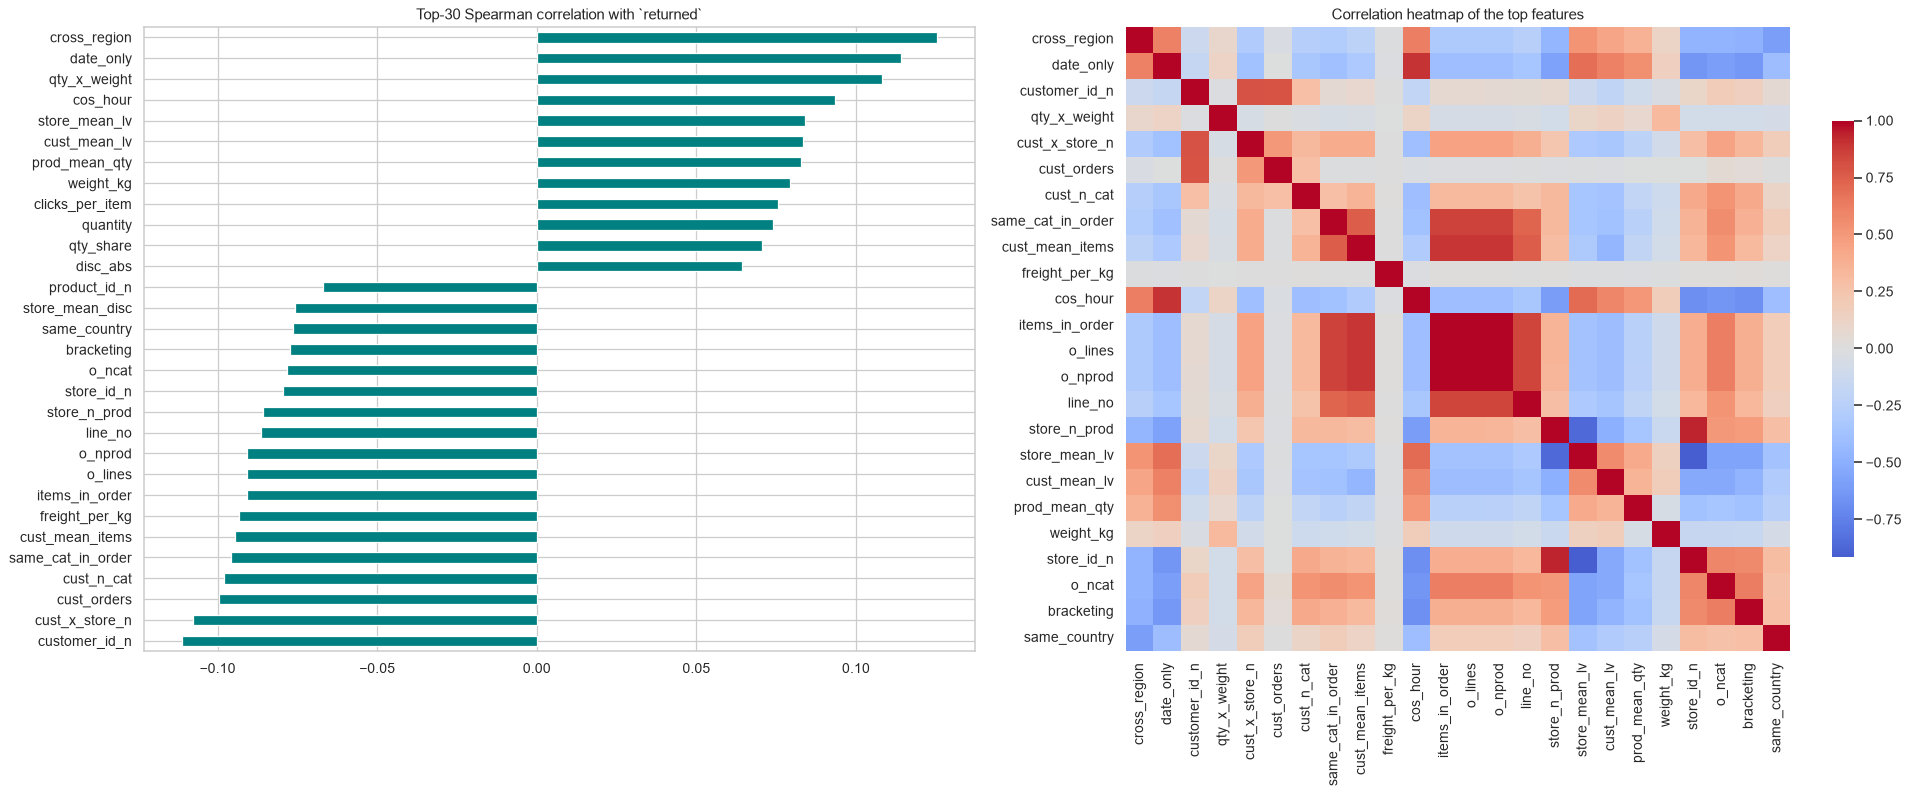

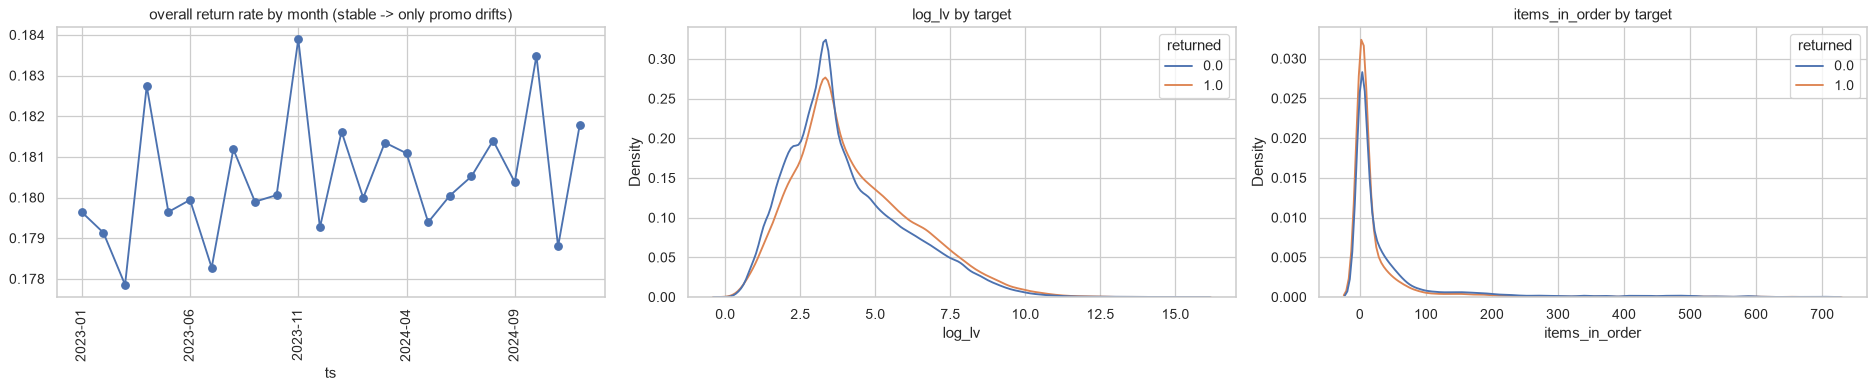

test rows whose customer / product / store never appear in train: 0.123 0.002 0.0


In [8]:
samp = T.sample(min(300000, len(T)), random_state=SEED); num_f = [c for c in NUM if c in samp.columns]
cor_t = samp[num_f].corrwith(samp.returned, method='spearman').dropna(); top = cor_t.abs().sort_values(ascending=False).head(30).index
fig, ax = plt.subplots(1, 2, figsize=(22, 9))
cor_t[top].sort_values().plot.barh(ax=ax[0], color='teal'); ax[0].set_title('Top-30 Spearman correlation with `returned`')
sns.heatmap(samp[list(top[:24])].corr(), cmap='coolwarm', center=0, ax=ax[1], cbar_kws={'shrink': .7}); ax[1].set_title('Correlation heatmap of the top features')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(21, 4.5))
T.groupby(T.ts.dt.to_period('M').astype(str)).returned.mean().iloc[1:-1].plot(ax=ax[0], marker='o'); ax[0].set_title('overall return rate by month (stable -> only promo drifts)'); ax[0].tick_params(axis='x', rotation=90)
for v, a in zip(['log_lv', 'items_in_order'], ax[1:]): sns.kdeplot(data=samp, x=v, hue='returned', common_norm=False, ax=a); a.set_title(v + ' by target')
plt.tight_layout(); plt.show()
print('test rows whose customer / product / store never appear in train:', round((~TEST.k_customer_id.isin(T.k_customer_id)).mean(), 3), round((~TEST.k_product_id.isin(T.k_product_id)).mean(), 3), round((~TEST.k_store_id.isin(T.k_store_id)).mean(), 4))

## 7. Target encoding, promo offset, switches, models
* **Target encoding** (smoothed, integer-key, vectorised): training rows get out-of-fold values (GroupKFold by order), validation/test rows use the full training part - no leakage. Single keys plus optional *pair* keys (customer x store, customer x product, ...).
* **Order-mates encoding:** returns cluster inside orders (std of per-order rate 0.22 vs 0.18 by chance), so the mean/max product-TE of the other lines in the same order is an optional feature.
* **Promo handling:** `drop` (default) or `offset` = the fading (month x promo) effect becomes a fixed logit offset (`init_score` / `base_margin` / `baseline`) so trees learn only the stable signal; no offset at prediction.
* **Switches** (`pairs`, `order_te`, `recency`, `drop_drift`, `promo`) are chosen automatically by forward selection on the latest time fold.

In [9]:
def target_encode(A, yA, B, cols, n_splits=5):
    '''Vectorised smoothed mean encoding on integer keys. OOF for A (by order group), full-A mapping for B.'''
    prior = yA.mean(); oof = {}; app = {}; folds = list(GroupKFold(n_splits).split(A, groups=A.k_order.values))
    for c in cols:
        k = TE_K[c]; code_ = A['k_' + c].values; K = int(max(code_.max(), B['k_' + c].values.max())) + 1; o = np.full(len(A), prior, dtype='float32')
        for a, b in folds:
            s = np.bincount(code_[a], weights=yA[a], minlength=K); n = np.bincount(code_[a], minlength=K); o[b] = ((s + k * prior) / (n + k))[code_[b]]
        s = np.bincount(code_, weights=yA, minlength=K); n = np.bincount(code_, minlength=K)
        oof[c + '_te'] = o; app[c + '_te'] = ((s + k * prior) / (n + k))[B['k_' + c].values].astype('float32')
    return pd.DataFrame(oof), pd.DataFrame(app)

def order_te(part, te_part):
    oc = pd.factorize(part.order_id.values)[0]; n = np.bincount(oc); out = {}
    for c in ['product_id_te', 'supplier_code_te']:
        v = te_part[c].values; out['o_mean_' + c] = (np.bincount(oc, weights=v) / n)[oc].astype('float32')
    out['o_max_product_te'] = pd.Series(te_part['product_id_te'].values).groupby(oc).transform('max').values.astype('float32')
    return pd.DataFrame(out)

def promo_offset(A_ts, A_promo, yA, k=50):
    '''logit of the smoothed (month x promo) return rate of the TRAIN part: captures the fading promo effect.'''
    d = pd.DataFrame({'m': A_ts.dt.to_period('M').astype(str).values, 'p': A_promo, 'y': yA}); d['mm'] = d.groupby('m').y.transform('mean')
    g = d.groupby(['m', 'p']).agg(s=('y', 'sum'), n=('y', 'size'), mm=('mm', 'first')).reset_index(); g['r'] = (g.s + k * g.mm) / (g.n + k)
    r = d.merge(g[['m', 'p', 'r']], on=['m', 'p'], how='left').r.values.clip(1e-3, 1 - 1e-3); return np.log(r / (1 - r)).astype('float32')

CFG0 = dict(promo='drop', pairs=False, order_te=False, recency=None, drop_drift=False)
feat_list = lambda cfg: [c for c in FEATS if not (cfg['drop_drift'] and c in DRIFT_FEATS)]
te_cols = lambda cfg: TE_BASE + (TE_PAIRS if cfg['pairs'] else [])
def make_X(part, te_part, cfg):
    X = pd.concat([part[feat_list(cfg)].reset_index(drop=True).astype('float32'), te_part.reset_index(drop=True)], axis=1)
    if cfg['order_te']: X = pd.concat([X, order_te(part.reset_index(drop=True), te_part.reset_index(drop=True))], axis=1)
    return X
def weights(part, cfg):
    if not cfg['recency']: return None
    d = (part.ts.max() - part.ts).dt.days.values; return (0.5 ** (d / cfg['recency'])).astype('float32')

LGB_PARAMS = dict(objective='binary', metric='auc', learning_rate=0.04, num_leaves=48, max_depth=8, min_child_samples=300, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l1=2.0, lambda_l2=15.0, max_bin=255, verbose=-1, num_threads=-1, seed=SEED)
XGB_PARAMS = dict(objective='binary:logistic', eval_metric='auc', tree_method='hist', eta=0.05, max_depth=7, min_child_weight=30, subsample=0.8, colsample_bytree=0.7, reg_lambda=15.0, reg_alpha=2.0, nthread=-1, seed=SEED)
CB_PARAMS = dict(learning_rate=0.08, depth=7, l2_leaf_reg=10, eval_metric='AUC', random_seed=SEED, thread_count=-1, verbose=0)
CB_CAT = ['customer_id', 'product_id', 'store_id']
def cb_X(part, X): return pd.concat([X, part[['k_' + c for c in CB_CAT]].reset_index(drop=True).astype(str).rename(columns=lambda c: c[2:] + '_cat')], axis=1)

def fit_lgb(XA, yA, off, w, XB=None, yB=None, rounds=LGB_ROUNDS, seed=SEED, lr=None):
    cats = [c for c in XA.columns if c in CATS]; dA = lgb.Dataset(XA, yA, weight=w, init_score=off, categorical_feature=cats, free_raw_data=False); p = dict(LGB_PARAMS, seed=seed)
    if lr: p['learning_rate'] = lr
    if XB is None: return lgb.train(p, dA, rounds)
    dB = lgb.Dataset(XB, yB, reference=dA, categorical_feature=cats); return lgb.train(p, dA, rounds, valid_sets=[dB], callbacks=[lgb.early_stopping(100 if lr is None else 50, verbose=False)])

def fit_lr(XA, yA, XB, XT=None, w=None):
    '''quantile->normal scaled numerics + one-hot categoricals -> L2 logistic regression (very different inductive bias).'''
    num = [c for c in XA.columns if c not in CATS]; cat = [c for c in XA.columns if c in CATS]
    sub = np.random.RandomState(0).choice(len(XA), min(300000, len(XA)), replace=False)
    qt = QuantileTransformer(n_quantiles=200, output_distribution='normal', subsample=300000, random_state=0).fit(XA[num].iloc[sub].fillna(0)); oh = OneHotEncoder(handle_unknown='ignore', min_frequency=50).fit(XA[cat])
    mk = lambda X: sparse.hstack([sparse.csr_matrix(qt.transform(X[num].fillna(0)).astype('float32')), oh.transform(X[cat])]).tocsr()
    lr = LogisticRegression(C=0.05, max_iter=300).fit(mk(XA), yA, sample_weight=w)
    return lr.predict_proba(mk(XB))[:, 1], (lr.predict_proba(mk(XT))[:, 1] if XT is not None else None)

def prep_fold(v0, v1, cfg):
    trm = (T.ts < v0).values; vam = ((T.ts >= v0) & (T.ts < v1)).values
    A, B = T[trm].reset_index(drop=True), T[vam].reset_index(drop=True); yA, yB = y_all[trm], y_all[vam]
    teA, teB = target_encode(A, yA, B, te_cols(cfg)); XA, XB = make_X(A, teA, cfg), make_X(B, teB, cfg)
    off = promo_offset(A.ts, T_promo[trm], yA) if cfg['promo'] == 'offset' else None
    return A, B, XA, XB, yA, yB, off, weights(A, cfg)

def run_fold(v0, v1, cfg, models=('lgb', 'xgb', 'cb', 'lr'), verbose=True):
    t0 = time.time(); A, B, XA, XB, yA, yB, off, w = prep_fold(v0, v1, cfg); out, iters = {}, {}
    if 'lgb' in models: m = fit_lgb(XA, yA, off, w, XB, yB); out['lgb'] = m.predict(XB, num_iteration=m.best_iteration); iters['lgb'] = m.best_iteration
    if 'xgb' in models and USE_XGB:
        dA = xgb.DMatrix(XA, label=yA, weight=w, base_margin=off); dB = xgb.DMatrix(XB, label=yB)
        m = xgb.train(XGB_PARAMS, dA, XGB_ROUNDS, evals=[(dB, 'val')], early_stopping_rounds=150, verbose_eval=False)
        out['xgb'] = m.predict(dB, iteration_range=(0, m.best_iteration + 1)); iters['xgb'] = m.best_iteration + 1
    if 'cb' in models and USE_CB:
        pa = Pool(cb_X(A, XA), yA, cat_features=[c + '_cat' for c in CB_CAT], baseline=off, weight=w); pb = Pool(cb_X(B, XB), yB, cat_features=[c + '_cat' for c in CB_CAT])
        m = CatBoostClassifier(iterations=CB_ROUNDS, early_stopping_rounds=100, **CB_PARAMS); m.fit(pa, eval_set=pb, use_best_model=True); out['cb'] = m.predict_proba(pb)[:, 1]; iters['cb'] = m.get_best_iteration() + 1
    if 'lr' in models and USE_LR: out['lr'], _ = fit_lr(XA, yA, XB, w=w)
    if verbose: print(f'fold [{v0} .. {v1}] | ' + ' | '.join(f'{k}: {roc_auc_score(yB, v):.4f}' for k, v in out.items()) + f' | {time.time()-t0:.0f}s', flush=True)
    return out, iters, yB

def quick_auc(v0, v1, cfg):
    '''fast LightGBM-only score used for switch selection'''
    A, B, XA, XB, yA, yB, off, w = prep_fold(v0, v1, cfg); m = fit_lgb(XA, yA, off, w, XB, yB, rounds=min(LGB_ROUNDS, 1500), lr=0.08)
    return roc_auc_score(yB, m.predict(XB, num_iteration=m.best_iteration))

## 8. Automatic switch selection on the latest (most test-like) fold

In [10]:
v0, v1 = FOLDS[-1]
# what happens if the promo code is naively used as a feature (the mistake that gives a good local but bad Kaggle score)?
A, B, XA, XB, yA, yB, off, w = prep_fold(v0, v1, CFG0); XA['promo'] = pd.factorize(T_promo[(T.ts < v0).values], sort=True)[0]; XB['promo'] = pd.Series(T_promo[((T.ts >= v0) & (T.ts < v1)).values]).map(dict(zip(sorted(set(T_promo)), range(10)))).values
m = fit_lgb(XA, yA, None, None, XB, yB, rounds=min(LGB_ROUNDS, 1500), lr=0.08); print('naive (promo as feature), latest fold: %.4f  <- inflated: this fold still contains a little of the promo effect, the 2025 test has none' % roc_auc_score(yB, m.predict(XB, num_iteration=m.best_iteration)))
del A, B, XA, XB, m; gc.collect()

cfg = dict(CFG0); best = quick_auc(v0, v1, cfg); log = [('base (promo dropped)', best)]
for sw, val in [('promo', 'offset'), ('pairs', True), ('order_te', True), ('recency', 270), ('drop_drift', True)]:
    trial = dict(cfg, **{sw: val}); s = quick_auc(v0, v1, trial); take = s > best + 0.0005
    log.append((f'+ {sw}={val}', s, 'KEEP' if take else 'skip'))
    if take: cfg, best = trial, s
    print(log[-1], flush=True)
print('\n==> selected config:', cfg, '| latest-fold LightGBM AUC: %.4f' % best)

naive (promo as feature), latest fold: 0.6872  <- inflated: this fold still contains a little of the promo effect, the 2025 test has none
('+ promo=offset', 0.7001987519204342, 'skip')
('+ pairs=True', 0.7095223408637898, 'KEEP')
('+ order_te=True', 0.7068457454320285, 'skip')
('+ recency=270', 0.7079431653454982, 'skip')
('+ drop_drift=True', 0.7046028205020229, 'skip')

==> selected config: {'promo': 'drop', 'pairs': True, 'order_te': False, 'recency': None, 'drop_drift': False} | latest-fold LightGBM AUC: 0.7095


## 9. Time-based cross-validation of all models

fold [2024-07-01 .. 2024-10-01] | lgb: 0.6992 | xgb: 0.6977 | cb: 0.6849 | lr: 0.6809 | 792s
fold [2024-10-01 .. 2025-01-02] | lgb: 0.7074 | xgb: 0.7036 | cb: 0.6944 | lr: 0.6853 | 2477s
                             lgb     xgb      cb      lr
fold1 (val 2024-07-01..)  0.6992  0.6977  0.6849  0.6809
fold2 (val 2024-10-01..)  0.7074  0.7036  0.6944  0.6853


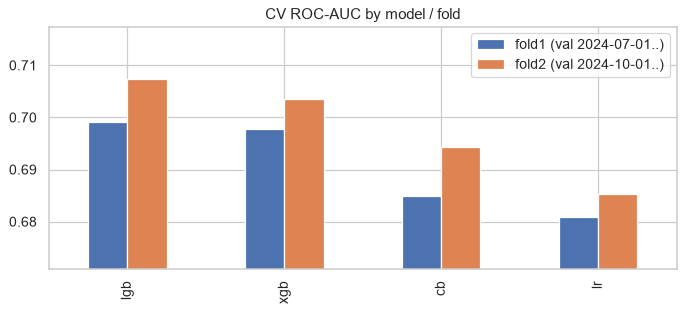

blend weights: {'lgb': np.float64(0.9), 'xgb': np.float64(0.1), 'cb': np.float64(0.0), 'lr': np.float64(0.0)} | weighted CV AUC 0.7047
blend per fold: [0.6994, 0.7074] | best single model per fold: [0.6992, 0.7074]


In [11]:
cv = [run_fold(a, b, cfg) for a, b in FOLDS]
names = list(cv[-1][0].keys())
cv_tbl = pd.DataFrame({n: [roc_auc_score(f[2], f[0][n]) for f in cv] for n in names}, index=[f'fold{i+1} (val {FOLDS[i][0]}..)' for i in range(len(cv))]); print(cv_tbl.round(4))
cv_tbl.T.plot.bar(figsize=(9, 3.5)); plt.ylim(cv_tbl.values.min() - .01, cv_tbl.values.max() + .01); plt.title('CV ROC-AUC by model / fold'); plt.show()

rk = lambda p: rankdata(p) / len(p)
R = [{n: rk(f[0][n]) for n in names} for f in cv]; fw = np.array([1.0] * (len(cv) - 1) + [2.0]); fw /= fw.sum()     # latest fold counts double
score = lambda i, w: roc_auc_score(cv[i][2], sum(wi * R[i][n] for wi, n in zip(w, names)))
grid = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(names)) if abs(sum(w) - 1) < 1e-6]
best_w, best_s = None, 0
for w in grid:
    s = sum(fw[i] * score(i, w) for i in range(len(cv)))
    if s > best_s: best_w, best_s = w, s
W = dict(zip(names, best_w)); print('blend weights:', {k: round(v, 2) for k, v in W.items()}, '| weighted CV AUC %.4f' % best_s)
print('blend per fold:', [round(score(i, best_w), 4) for i in range(len(cv))], '| best single model per fold:', cv_tbl.max(axis=1).round(4).tolist())

## 10. Final fit on all training data -> `submission.csv`

In [12]:
teF, teT = target_encode(T, y_all, TEST, te_cols(cfg)); XF, XT = make_X(T, teF, cfg), make_X(TEST, teT, cfg)
offF = promo_offset(T.ts, T_promo, y_all) if cfg['promo'] == 'offset' else None; wF = weights(T, cfg)
iters = {n: int(np.mean([f[1][n] for f in cv]) * 1.15) for n in names if n != 'lr'}; final = {}
if 'lgb' in names:
    ps = []
    for s in range(3):
        m = fit_lgb(XF, y_all, offF, wF, rounds=iters['lgb'], seed=SEED + s); ps.append(rk(m.predict(XT)))
        if s == 0: imp = pd.Series(m.feature_importance('gain'), index=XF.columns).sort_values()
    final['lgb'] = np.mean(ps, axis=0); print('lgb done')
if 'xgb' in names:
    m = xgb.train(XGB_PARAMS, xgb.DMatrix(XF, label=y_all, weight=wF, base_margin=offF), iters['xgb']); final['xgb'] = rk(m.predict(xgb.DMatrix(XT))); print('xgb done')
if 'cb' in names:
    pf = Pool(cb_X(T, XF), y_all, cat_features=[c + '_cat' for c in CB_CAT], baseline=offF, weight=wF); pt = Pool(cb_X(TEST, XT), cat_features=[c + '_cat' for c in CB_CAT])
    m = CatBoostClassifier(iterations=iters['cb'], **CB_PARAMS); m.fit(pf); final['cb'] = rk(m.predict_proba(pt)[:, 1]); print('cb done')
if 'lr' in names:
    _, p = fit_lr(XF, y_all, XF.iloc[:5], XT, w=wF); final['lr'] = rk(p); print('lr done')
blend = sum(W[n] * final[n] for n in names)
sub = pd.DataFrame({'order_line_id': TEST.order_line_id.values, 'returned': blend}); sub.to_csv('submission4.csv', index=False)
print(sub.shape, '| nulls:', int(sub.returned.isnull().sum()), '| unique ids:', sub.order_line_id.nunique(), '| range %.3f-%.3f' % (blend.min(), blend.max()))
sub.head()

lgb done
xgb done
cb done
lr done
(479995, 2) | nulls: 0 | unique ids: 479995 | range 0.000-1.000


,order_line_id,returned
0,L85d608999fa1ee,0.383532
1,L86272cb9543018,0.953091
2,L66b5669bdace5b,0.336968
3,L2c5886124612de,0.905502
4,L56fe7aa5ac5dd8,0.231477


       lgb    xgb     cb     lr
lgb  1.000  0.982  0.950  0.907
xgb  0.982  1.000  0.939  0.898
cb   0.950  0.939  1.000  0.921
lr   0.907  0.898  0.921  1.000


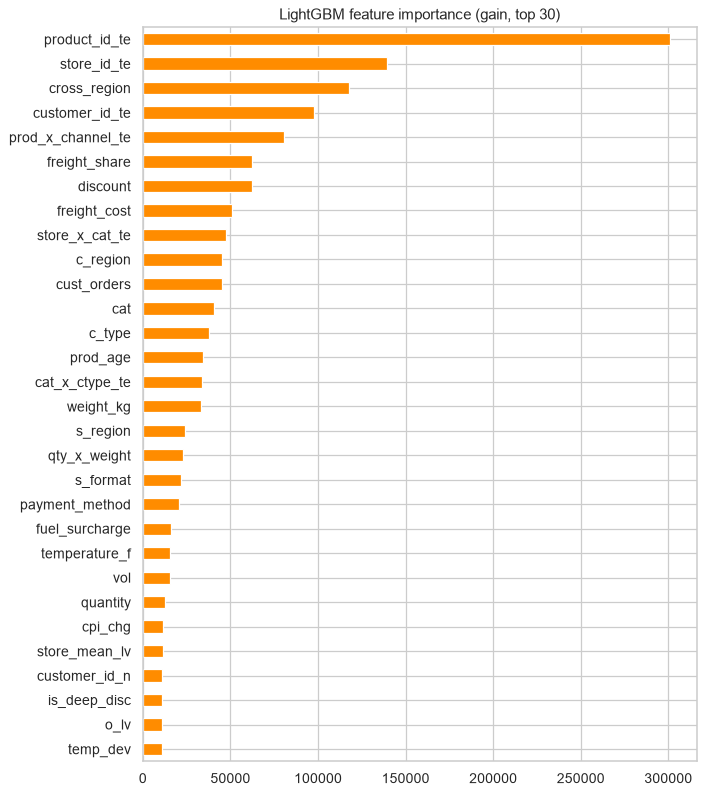

: 

In [ ]:
print(pd.DataFrame(final).corr(method='spearman').round(3))                                   # model agreement
imp.tail(30).plot.barh(figsize=(8, 9), color='darkorange'); plt.title('LightGBM feature importance (gain, top 30)'); plt.tight_layout(); plt.show()

## Notes
* Trust the **latest-fold** AUC (section 9): it is the closest proxy of the 2025 test. If Kaggle differs a lot from it, the first suspects are: any feature that drifts in time (compare with the stability heatmap), then the target-encoding switches.
* The **promo code** is intentionally never a plain feature. If you ever see a model with 0.64 locally and 0.55 on Kaggle, re-check that it is not leaking back in.
* Useful extras if you have more compute: Optuna on `num_leaves / min_child_samples / feature_fraction` using the latest fold, more LightGBM seeds, a neural net with ID embeddings as a fifth blend member.